# Lesson 4.1: Sampling Variability and Sampling Distributions

Draw 1,000 samples from a skewed population and watch the sample means form a bell-shaped sampling distribution centred on the true mean.

Part of *Statistics from Scratch*. Run each cell with **Shift + Enter**, top to bottom.

If a package is missing on your computer, run the next cell once. In Google Colab everything is already installed.

In [ ]:
%pip install -q numpy scipy pandas statsmodels matplotlib

## 1. Build a population

A made-up population of 100,000 values, skewed to the right (a few large values), with a true mean near 30 and a true SD near 15, like the lesson's builder. The seed makes the numbers repeatable.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
population = 15 + rng.exponential(15, size=100_000)
mu = population.mean()
sigma = population.std()

print(f'population mean (mu)   = {mu:.2f}')
print(f'population SD (sigma)  = {sigma:.2f}')

population mean (mu)   = 30.05
population SD (sigma)  = 15.08


## 2. Draw 1,000 samples of size 30

Each row below is one random sample of 30 people. We compute the mean of every row, so we end up with 1,000 different sample means. That pile of means is the sampling distribution.

In [2]:
n = 30
samples = rng.choice(population, size=(1000, n))
sample_means = samples.mean(axis=1)

print('first five sample means:', sample_means[:5].round(2))
print('number of sample means:', len(sample_means))

first five sample means: [30.09 34.36 30.63 27.59 31.43]
number of sample means: 1000


## 3. Centre and spread

The sample means should centre on mu, and their spread (the standard error) should be close to sigma divided by the square root of n.

In [3]:
print(f'mean of the sample means = {sample_means.mean():.2f}  (mu = {mu:.2f})')
print(f'SD of the sample means    = {sample_means.std(ddof=1):.2f}')
print(f'theory sigma / sqrt(n)    = {sigma / np.sqrt(n):.2f}')

mean of the sample means = 29.99  (mu = 30.05)
SD of the sample means    = 2.83
theory sigma / sqrt(n)    = 2.75


## 4. Draw the sampling distribution

A histogram shows the shape. Even though the population is skewed, the sample means pile up in a fairly symmetric bell around mu. The dashed line marks mu.

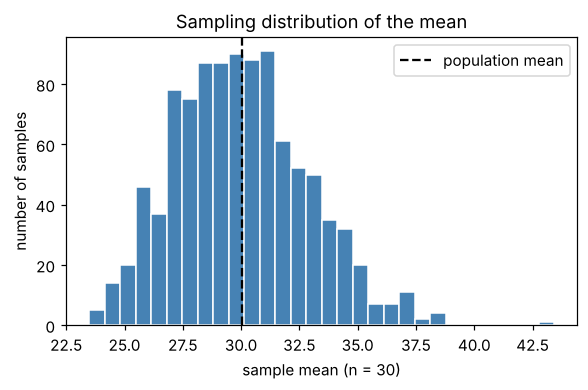

In [4]:
plt.figure(figsize=(6, 3.4))
plt.hist(sample_means, bins=30, color='steelblue', edgecolor='white')
plt.axvline(mu, color='black', linestyle='--', label='population mean')
plt.xlabel('sample mean (n = 30)')
plt.ylabel('number of samples')
plt.title('Sampling distribution of the mean')
plt.legend()
plt.show()

## Try this

- Change n to 100 and predict the new SD of the sample means (sigma divided by 10), then run it.
- Change 1000 samples to 100 and see how much the histogram looks rougher.
- Replace the exponential population with rng.uniform(0, 60, 100_000). Does the sampling distribution still look like a bell?

## The same idea in R, SPSS and Stata

**R**

```r
set.seed(42)
population <- 15 + rexp(100000, rate = 1/15)
means <- replicate(1000, mean(sample(population, 30, replace = TRUE)))
mean(population)
mean(means)
sd(means)
15 / sqrt(30)
hist(means, breaks = 30)
```

**SPSS** (Transform > Compute Variable (with Random Number Functions), then Analyze > Descriptive Statistics > Descriptives)

```
SET SEED=42.
INPUT PROGRAM.
LOOP s = 1 TO 1000.
COMPUTE total = 0.
LOOP i = 1 TO 30.
COMPUTE total = total + 15 + RV.EXP(1/15).
END LOOP.
COMPUTE xbar = total/30.
END CASE.
END LOOP.
END FILE.
END INPUT PROGRAM.
DESCRIPTIVES VARIABLES=xbar /STATISTICS=MEAN STDDEV.
```

**Stata**

```
clear
set seed 42
set obs 1000
generate xbar = 0
forvalues i = 1/30 {
    quietly replace xbar = xbar + (15 + rexponential(15)) / 30
}
summarize xbar
display 15 / sqrt(30)
histogram xbar
```